# 03 — Hipótesis longitudinal con datos reales (EMBED)

**El flujo central del TFG (O7/O8), ejecutable de principio a fin.** Pregunta:
en mujeres a las que se diagnosticó un cáncer en un cribado, ¿había ya una
señal topológica en el cribado anterior, leído como normal?

- **Anticipación**: descriptores de persistencia de la exploración previa (t-1) **sola**.
- **Deriva**: distancia *bottleneck* entre los diagramas de t-1 y t.
- **Control positivo**: la exploración t sola, con el cáncer ya presente. Si
  ni siquiera t separa casos de controles, el descriptor no ve la lesión y un
  nulo de anticipación no informa de nada.

El diseño es una **cohorte de cribado emparejada** (sección 3). Es la tercera
versión: las dos anteriores tenían confusores que producían señales falsas,
y la sección 10 los reproduce como caso de estudio metodológico.

Reutiliza el mismo código que los scripts (`download_embed_longitudinal.py`,
`embed_longitudinal_evaluation.py`, `embed_lesion_site.py`): el notebook es la
vista interactiva; los scripts, la reproducción de un tirón.

## Requisitos previos (una sola vez)

1. **Acceso a EMBED concedido** (acceso controlado; pasos en
   `docs/acceso_datasets_longitudinales.pdf`).
2. **Credenciales AWS** en `~/.aws/credentials`, perfil `[emory-embed]`.
   *Nunca* pongas las claves en el notebook ni en ningún fichero del repo.
3. **Imágenes descargadas**:
   `python scripts/download_embed_longitudinal.py --cribado --n-incident 1000`
   (y, solo para la sección 10, los diseños anteriores: ver allí).
4. Dependencias: `pip install -r requirements.txt` (incluye `boto3` y
   `pylibjpeg`: los DICOM de EMBED vienen en JPEG Lossless).

Cita obligatoria del dataset: *EMory BrEast Imaging Dataset (EMBED). HITI Lab,
Emory University.*


## 0. Imports y configuración

In [1]:
from __future__ import annotations

import ast
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

from src.topology import backend
from src.preprocessing import read_dicom_gray
import download_embed_longitudinal as dl
import embed_longitudinal_evaluation as ev
import embed_lesion_site as ls

EMBED_DIR = ROOT / "data" / "embed"
rf = lambda: RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)
print("Backend TDA activo:", backend())


Backend TDA activo: gudhi


## 1. Tablas de metadatos clínicos

`clinical.csv` tiene una fila por hallazgo (BI-RADS `asses`, tipo de
exploración `desc`, anatomía patológica `path_severity`, lado `side`) y
`metadata_reduced.csv` una fila por imagen (ruta S3, vista, si es una vista
ampliada `spot_mag`, ROI anotadas). Se descargan solo si faltan.

In [2]:
import boto3

EMBED_DIR.mkdir(parents=True, exist_ok=True)
TABLAS = {
    "clinical.csv": "tables/EMBED_OpenData_clinical.csv",
    "metadata_reduced.csv": "tables/EMBED_OpenData_metadata_reduced.csv",
}
faltan = {local: remota for local, remota in TABLAS.items() if not (EMBED_DIR / local).exists()}
if faltan:
    s3 = boto3.Session(profile_name="emory-embed", region_name="us-west-2").client("s3")
    for local, remota in faltan.items():
        print(f"Descargando {remota}...")
        s3.download_file("embed-dataset-open", remota, str(EMBED_DIR / local))
else:
    print("Tablas ya descargadas.")


Tablas ya descargadas.


## 2. Estructura longitudinal de EMBED

Una fila por exploración (`dl._exam_table`): fecha, si es de cribado, si
tiene un cáncer confirmado por anatomía patológica.

23253 pacientes, 72770 exploraciones
14789 pacientes con 2+ exploraciones
77% de las exploraciones son de cribado
658 pacientes con cáncer confirmado por patología


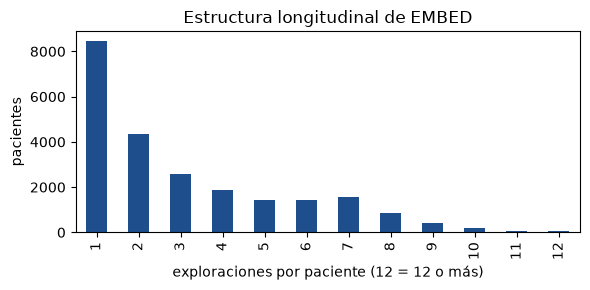

In [3]:
examenes = dl._exam_table(EMBED_DIR / "clinical.csv")
por_paciente = examenes.groupby("empi_anon").size()
print(f"{examenes['empi_anon'].nunique()} pacientes, {len(examenes)} exploraciones")
print(f"{(por_paciente >= 2).sum()} pacientes con 2+ exploraciones")
print(f"{examenes['screen'].mean():.0%} de las exploraciones son de cribado")
print(f"{examenes.loc[examenes['malig'], 'empi_anon'].nunique()} pacientes con cáncer confirmado por patología")

fig, ax = plt.subplots(figsize=(6, 3))
por_paciente.clip(upper=12).value_counts().sort_index().plot.bar(ax=ax, color="#1F4E8C")
ax.set_xlabel("exploraciones por paciente (12 = 12 o más)"); ax.set_ylabel("pacientes")
ax.set_title("Estructura longitudinal de EMBED")
plt.tight_layout(); plt.show()


## 3. Diseño: cohorte de cribado emparejada

`dl.build_screening_cohort` (en terminal: `--cribado`):

- **Casos**: cáncer confirmado por anatomía patológica (`path_severity` 0 =
  invasivo, 1 = in situ) **detectado en un cribado**. t = el último cribado
  hasta 180 días antes del diagnóstico; t-1 = el último cribado con
  resultado normal/benigno al menos 180 días antes de t.
- **Controles**: mujeres sin patología maligna y con todas sus exploraciones
  normales/benignas; dos cribados emparejados 1:1 con un caso por
  **intervalo** (±90 días), **fecha de t-1** (±1 año) y **misma vista**.
- **Imágenes**: solo mamografía 2D de campo completo (sin compresión focal
  ni magnificación), de la mama del lado del cáncer, MLO preferente.

Cada restricción responde a un confusor encontrado en los diseños
anteriores (sección 10).

In [4]:
manifest = pd.read_csv(EMBED_DIR / "longitudinal_manifest_cribado.csv")
y = (manifest["kind"] == "incidente").astype(int).values
print(f"{len(manifest)} pacientes: {y.sum()} cánceres, {(1 - y).sum()} controles emparejados")
manifest.head()


324 pacientes: 162 cánceres, 162 controles emparejados


,empi_anon,kind,view,acc_t0,acc_t1,path_t0,path_t1,matched_to
0,10173804,incidente,L_MLO,9279333627718411,7180728150657133,data/embed/images/cribado_incidente_10173804/t...,data/embed/images/cribado_incidente_10173804/t...,NaN
1,81561772,control,L_MLO,5972663863642927,5452219531577766,data/embed/images/cribado_control_81561772/t0.dcm,data/embed/images/cribado_control_81561772/t1.dcm,10173804.0
2,11513410,incidente,L_MLO,9408596600594211,7176103736989608,data/embed/images/cribado_incidente_11513410/t...,data/embed/images/cribado_incidente_11513410/t...,NaN
3,11134206,control,L_MLO,2086677415416979,1817639645145090,data/embed/images/cribado_control_11134206/t0.dcm,data/embed/images/cribado_control_11134206/t1.dcm,11513410.0
4,11579484,incidente,L_MLO,6193863126165241,9225361797574411,data/embed/images/cribado_incidente_11579484/t...,data/embed/images/cribado_incidente_11579484/t...,NaN


### ¿Están equilibrados los grupos?

Un diseño emparejado tiene que dejar los grupos iguales en todo lo que no
sea la enfermedad. Intervalo, año de t-1, edad y densidad mamaria (BI-RADS
1–4), con Mann-Whitney.

In [5]:
cov = manifest[["empi_anon", "kind", "acc_t0", "acc_t1"]].copy()
cov["intervalo_dias"] = ev.intervals_days(manifest)
fecha = examenes.set_index(["empi_anon", "acc_anon"])["date"]
cov["anio_t0"] = [fecha[(r.empi_anon, r.acc_t0)].year for r in manifest.itertuples()]
clin = pd.read_csv(EMBED_DIR / "clinical.csv", usecols=["empi_anon", "acc_anon", "age_at_study", "tissueden"])
clin = clin.groupby(["empi_anon", "acc_anon"]).first()
claves_t0 = list(zip(cov["empi_anon"], cov["acc_t0"]))
cov["edad_t0"] = clin["age_at_study"].reindex(claves_t0).values
cov["densidad_t0"] = clin["tissueden"].reindex(claves_t0).values

filas = []
for var in ["intervalo_dias", "anio_t0", "edad_t0", "densidad_t0"]:
    a, b = cov.loc[y == 1, var].dropna(), cov.loc[y == 0, var].dropna()
    filas.append({"variable": var, "casos (mediana)": a.median(), "controles (mediana)": b.median(),
                  "p (Mann-Whitney)": stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(filas).round(3)


,variable,casos (mediana),controles (mediana),p (Mann-Whitney)
0,intervalo_dias,385.000,390.500,0.784
1,anio_t0,2016.000,2016.000,0.901
2,edad_t0,66.386,62.987,0.003
3,densidad_t0,2.000,2.000,0.504


## 4. Un par real (t-1, t) de cada clase

Arriba un caso: t-1 leída como normal y t con el cáncer (recuadro: la ROI
anotada en EMBED, cuando existe). Abajo, su control emparejado.

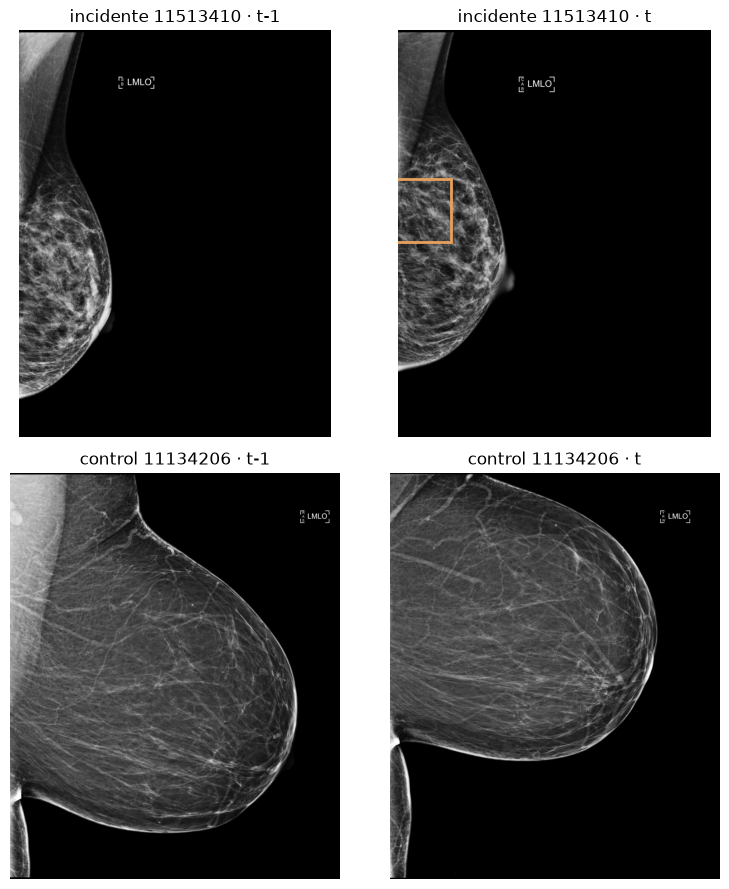

In [6]:
rois = ls.lesion_rois(manifest)
caso = manifest[(manifest["kind"] == "incidente") & manifest["empi_anon"].isin(rois)].iloc[0]
control = manifest[manifest["matched_to"] == caso["empi_anon"]].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(8, 9))
for i, fila in enumerate([caso, control]):
    for j, (col, t) in enumerate([("path_t0", "t-1"), ("path_t1", "t")]):
        img = read_dicom_gray(ROOT / fila[col])
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].set_title(f"{fila['kind']} {fila['empi_anon']} · {t}")
        axes[i, j].axis("off")
r, c = rois[int(caso["empi_anon"])]
axes[0, 1].add_patch(plt.Rectangle((c - ls.HALF, r - ls.HALF), 2 * ls.HALF, 2 * ls.HALF,
                                   fill=False, edgecolor="#E8A15C", lw=2))
plt.tight_layout(); plt.show()


## 5. Señales globales: la mamografía entera

Diagrama de persistencia de la mamografía completa reducida a 224×224 →
imagen de persistencia (anticipación) y distancia bottleneck H0/H1 entre t-1
y t (deriva, con `max_points=100`). Las features se guardan en caché en
`data/embed/`; la primera ejecución tarda ~1 s por imagen.

intervalo solo        : AUC = 0.503 ± 0.043


anticipación (t-1)    : AUC = 0.459 ± 0.024


deriva (t-1 vs t)     : AUC = 0.535 ± 0.012


control positivo (t)  : AUC = 0.530 ± 0.023


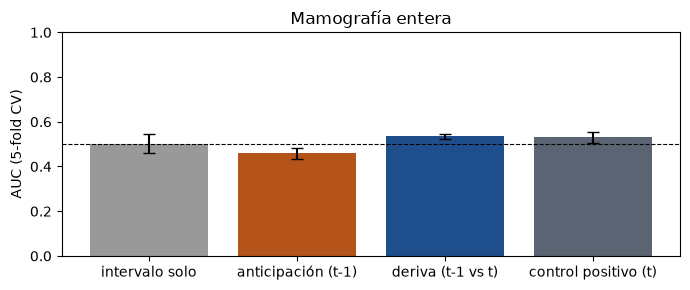

In [7]:
X_anticipacion, X_deriva, _ = ev.compute_features(manifest, n_bins=6, verbose=False)
X_t = ev.compute_t1_features(manifest, n_bins=6, verbose=False)
dias = cov["intervalo_dias"].values[:, None]

senales_globales = {
    "intervalo solo": dias,
    "anticipación (t-1)": X_anticipacion,
    "deriva (t-1 vs t)": X_deriva,
    "control positivo (t)": X_t,
}
res_global = {}
for nombre, X in senales_globales.items():
    s = cross_val_score(rf(), X, y, cv=5, scoring="roc_auc")
    res_global[nombre] = (s.mean(), s.std())
    print(f"{nombre:22s}: AUC = {s.mean():.3f} ± {s.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(res_global), [m for m, _ in res_global.values()], yerr=[s for _, s in res_global.values()],
       capsize=4, color=["#999999", "#B4531A", "#1F4E8C", "#5B6472"])
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("AUC (5-fold CV)"); ax.set_title("Mamografía entera")
plt.tight_layout(); plt.show()


**Lectura**: todo al azar, **incluido el control positivo**. El
descriptor global no ve una lesión de cribado ni siquiera cuando está
presente: reducida a 224×224, una lesión de 1 cm ocupa unos pocos píxeles.
Así que el nulo de anticipación global no dice nada sobre el precursor;
hace falta mirar donde está la lesión.

### ¿Resolución o dilución?

Dos explicaciones de la ceguera global: a 224×224 la lesión son pocos
píxeles (**resolución**), o aunque se vea es un rasgo entre miles de la mama
entera (**dilución**). `scripts/embed_global_resolution.py` repite el
control positivo con la mama recortada a su caja y reducida a 224, 512 y
1024 px.

In [8]:
import embed_global_resolution as gr
import pickle

cache_res = pickle.loads(gr.CACHE_PATH.read_bytes()) if gr.CACHE_PATH.exists() else {}
claves = [(p, gr.SIZES, gr.N_BINS, gr.VERSION) for p in manifest["path_t1"]]
if all(k in cache_res for k in claves):
    for s in gr.SIZES:
        X = np.stack([cache_res[k][s] for k in claves])
        sc = cross_val_score(rf(), X, y, cv=5, scoring="roc_auc")
        print(f"control positivo global a {s:4d} px: AUC = {sc.mean():.3f} ± {sc.std():.3f}")
else:
    print("Ejecuta antes: python scripts/embed_global_resolution.py")


control positivo global a  224 px: AUC = 0.549 ± 0.113


control positivo global a  512 px: AUC = 0.587 ± 0.096


control positivo global a 1024 px: AUC = 0.600 ± 0.066


El AUC sube algo con la resolución (≈0.55 → ≈0.60) pero no llega al
≈0.67 de una ventana en la lesión (sección 6): pesa más la **dilución**.

## 6. Señales en el sitio de la lesión

`scripts/embed_lesion_site.py`, para los casos cuya imagen t tiene ROI
anotada:

1. Centro de la ROI en t → posición **relativa** dentro de la caja de la mama.
2. La misma posición relativa en t-1 del caso y en t y t-1 de su control
   emparejado. La ubicación la fija la anotación del caso y se aplica igual
   al control: no hay sesgo de selección del sitio.
3. Ventana de 512×512 px a resolución completa (~3.3 cm con píxel de
   0.065 mm) → 256×256 → CLAHE → homología cúbica.

La validación cruzada agrupa por par (`GroupKFold`): un caso y su control
nunca quedan uno en entrenamiento y otro en test. La significación se mide
con una **prueba de permutación dentro de pares** (intercambiar al azar las
etiquetas de caso y control de cada par).

In [9]:
res_sitio = {}
for half in (256, 512):
    ls.HALF = half
    feats, y_s, grupos = ls.compute_site_features(manifest, verbose=False)
    for nombre, clave in [("control positivo (t)", "pi_t1"), ("anticipación (t-1)", "pi_t0"), ("deriva", "drift")]:
        X = np.stack([f[clave] for f in feats])
        # en el diseño 1:1 cada par es a la vez el grupo de la CV y el conjunto de la permutación
        res_sitio[(nombre, 2 * half)] = ls.permutation_auc(X, y_s, grupos, grupos, n=100)
ls.HALF = 256
print(f"{len(y_s) // 2} pares caso-control con ROI anotada")
pd.DataFrame({f"ventana {v} px": {n: f"{a:.3f} (p = {p:.2f})" for (n, w), (a, p) in res_sitio.items() if w == v}
              for v in (512, 1024)})


82 pares caso-control con ROI anotada


,ventana 512 px,ventana 1024 px
control positivo (t),0.661 (p = 0.01),0.629 (p = 0.03)
anticipación (t-1),0.499 (p = 0.54),0.589 (p = 0.07)
deriva,0.506 (p = 0.48),0.477 (p = 0.67)


**Lectura**:

- **Control positivo en el sitio de la lesión ≈ 0.67, significativo**: mirando
  donde está, la topología sí detecta el cáncer. Es coherente con el ≈0.66 de
  CBIS-DDSM (notebook 02), que también trabaja con la lesión recortada.
- **Anticipación en el mismo sitio, un cribado antes ≈ 0.50**: sin señal.
- Con una ventana del doble (1024 px, por si la alineación sin registro
  entre exploraciones falla) la anticipación sube a ≈0.59 sin llegar a ser
  significativa: a revisar con más pares.

Es un **nulo informativo**: el método ve la lesión cuando está, y no ve nada
en ese sitio aproximadamente un año antes.

### Las ventanas, a ojo

Ventana del sitio de la lesión en las cuatro imágenes del par mostrado en la
sección 4.

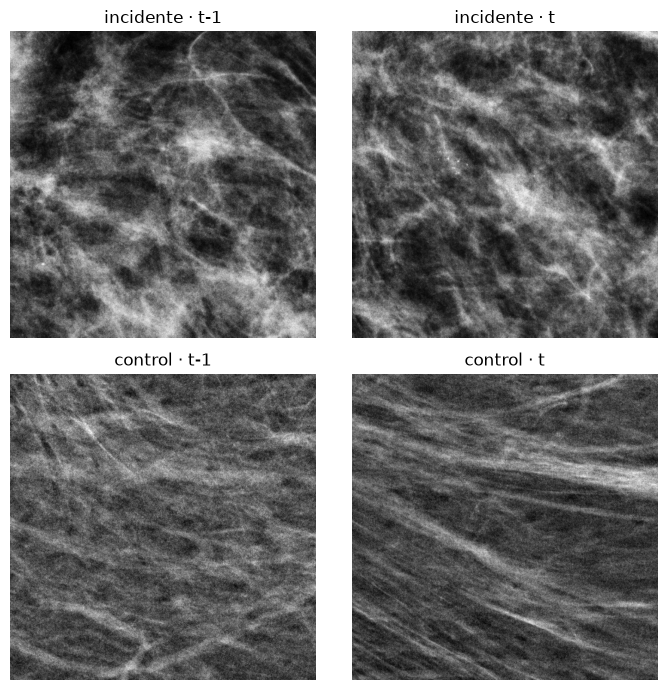

In [10]:
from src.local_topology import map_point, window_around

def ventanas(fila_ref, fila):
    r_ref, c_ref = rois[int(fila_ref["empi_anon"])]
    bbox_ref = ls._full_bbox(read_dicom_gray(ROOT / fila_ref["path_t1"]))
    out = []
    for col in ("path_t0", "path_t1"):
        a = read_dicom_gray(ROOT / fila[col])
        r, c = map_point(r_ref, c_ref, bbox_ref, ls._full_bbox(a))
        out.append(window_around(a, r, c, ls.HALF))
    return out

fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for i, fila in enumerate([caso, control]):
    for j, (win, t) in enumerate(zip(ventanas(caso, fila), ["t-1", "t"])):
        axes[i, j].imshow(win, cmap="gray"); axes[i, j].axis("off")
        axes[i, j].set_title(f"{fila['kind']} · {t}")
plt.tight_layout(); plt.show()


## 6b. Más datos: todas las vistas y tres controles por caso

La versión abierta de EMBED no tiene más cánceres elegibles (658
confirmados → 313 con un cribado en el diagnóstico → 162 con un cribado
negativo previo). Para ganar datos en el análisis en el sitio de la lesión,
la **cohorte de lesión** (`download_embed_longitudinal.py --lesion`) usa:

- **todas las vistas** del lado del cáncer con ROI anotada en t (MLO y CC),
  con la ROI de la misma imagen que se descarga;
- **tres controles** por vista, con los mismos criterios de emparejamiento.

La validación cruzada agrupa por **paciente del caso** (sus dos vistas y sus
controles caen siempre en el mismo fold) y la permutación elige al azar,
dentro de cada caso y sus controles, cuál hace de caso.

In [11]:
MANIFIESTO_LESION = EMBED_DIR / "longitudinal_manifest_lesion.csv"
res_lesion = {}
if MANIFIESTO_LESION.exists():
    m_les = pd.read_csv(MANIFIESTO_LESION)
    for half in (256, 512):
        ls.HALF = half
        feats_l, y_l, grupos_l, sets_l = ls.compute_lesion_cohort_features(m_les, verbose=False)
        for nombre, clave in [("control positivo (t)", "pi_t1"), ("anticipación (t-1)", "pi_t0"), ("deriva", "drift")]:
            X = np.stack([f[clave] for f in feats_l])
            res_lesion[(nombre, 2 * half)] = ls.permutation_auc(X, y_l, grupos_l, sets_l, n=100)
    ls.HALF = 256
    print(f"{int(y_l.sum())} vistas con lesión de {m_les.loc[y_l == 1, 'empi_anon'].nunique()} cánceres, "
          f"{int((1 - y_l).sum())} controles")
    display(pd.DataFrame({f"ventana {v} px": {n: f"{a:.3f} (p = {p:.2f})"
                                              for (n, w), (a, p) in res_lesion.items() if w == v}
                          for v in (512, 1024)}))
else:
    print("Ejecuta antes: python scripts/download_embed_longitudinal.py --lesion")


174 vistas con lesión de 97 cánceres, 522 controles


,ventana 512 px,ventana 1024 px
control positivo (t),0.693 (p = 0.01),0.636 (p = 0.01)
anticipación (t-1),0.569 (p = 0.04),0.534 (p = 0.21)
deriva,0.577 (p = 0.03),0.486 (p = 0.61)


Con más datos, la anticipación en el sitio (ventana de 512 px) sale
≈0.57 y la permutación da p < 0.05. Antes de creerlo hay que pasar los
mismos filtros que tumbaron las señales anteriores. La cohorte no está
emparejada por **edad** ni por **densidad**, y una t-1 "normal" puede ser
BI-RADS **N** (nada) o **B** (hallazgo benigno anotado): si los casos
tuvieran más B, la topología podría estar viendo algo que el radiólogo ya
vio.

In [12]:
from sklearn.model_selection import cross_val_predict
from statsmodels.discrete.conditional_models import ConditionalLogit

ls.HALF = 256
feats_l, y_l, grupos_l, sets_l = ls.compute_lesion_cohort_features(m_les, verbose=False)
Xa_l = np.stack([f["pi_t0"] for f in feats_l])
claves = list(zip(m_les["empi_anon"], m_les["acc_t0"]))
edad_l = clin["age_at_study"].reindex(claves).astype(float).values
den_l = clin["tissueden"].reindex(claves).astype(float).values
edad_l = np.where(np.isnan(edad_l), np.nanmedian(edad_l), edad_l)
den_l = np.where(np.isnan(den_l), np.nanmedian(den_l), den_l)
asses = examenes.set_index(["empi_anon", "acc_anon"])["asses"]
b_l = np.array([("B" in asses.get(k, set())) for k in claves], dtype=float)

print("Balance casos vs controles:")
print(f"  edad      {edad_l[y_l == 1].mean():.1f} vs {edad_l[y_l == 0].mean():.1f}  "
      f"(Mann-Whitney p = {stats.mannwhitneyu(edad_l[y_l == 1], edad_l[y_l == 0]).pvalue:.1g})")
print(f"  densidad  {den_l[y_l == 1].mean():.2f} vs {den_l[y_l == 0].mean():.2f}  "
      f"(p = {stats.mannwhitneyu(den_l[y_l == 1], den_l[y_l == 0]).pvalue:.2f})")
print(f"  t-1 con B {b_l[y_l == 1].mean():.0%} vs {b_l[y_l == 0].mean():.0%}")

# score de anticipación fuera de fold y regresión logística CONDICIONAL: cada caso
# solo se compara con sus propios controles
cv = GroupKFold(5)
score = cross_val_predict(rf(), Xa_l, y_l, groups=grupos_l, cv=cv, method="predict_proba")[:, 1]
z = lambda v: (v - v.mean()) / v.std()
print()
print("Regresión logística condicional (OR por desviación típica del score):")
for etiqueta, exog in [("score solo", np.c_[z(score)]),
                       ("+ edad + densidad + B en t-1", np.c_[z(score), z(edad_l), den_l, b_l])]:
    r = ConditionalLogit(y_l, exog, groups=sets_l).fit(disp=0)
    print(f"  {etiqueta:30s}: OR = {np.exp(r.params[0]):.2f}, p = {r.pvalues[0]:.3g}")
rho = stats.spearmanr(score[y_l == 0], edad_l[y_l == 0])
print(f"  score de anticipación vs edad en controles: Spearman rho = {rho.statistic:.2f} (p = {rho.pvalue:.2f})")

print()
print("Sensibilidad:")
for etiqueta, mk in [("solo MLO", m_les["view"].str.endswith("_MLO").values),
                     ("solo CC", m_les["view"].str.endswith("_CC").values),
                     ("un control por caso (1:1)", m_les.groupby("set_id").cumcount().values <= 1)]:
    s = cross_val_score(rf(), Xa_l[mk], y_l[mk], groups=grupos_l[mk], cv=cv, scoring="roc_auc")
    print(f"  {etiqueta:26s}: AUC = {s.mean():.3f} ± {s.std():.3f}")


Balance casos vs controles:
  edad      64.2 vs 60.9  (Mann-Whitney p = 0.0002)
  densidad  2.40 vs 2.34  (p = 0.29)
  t-1 con B 17% vs 7%



Regresión logística condicional (OR por desviación típica del score):
  score solo                    : OR = 1.28, p = 0.00663
  + edad + densidad + B en t-1  : OR = 1.30, p = 0.00684
  score de anticipación vs edad en controles: Spearman rho = -0.01 (p = 0.73)

Sensibilidad:


  solo MLO                  : AUC = 0.566 ± 0.055


  solo CC                   : AUC = 0.571 ± 0.016


  un control por caso (1:1) : AUC = 0.528 ± 0.085


**Lectura**:

- Los casos son **unos 3 años mayores** y su t-1 tiene **más B** (≈17 %
  frente a ≈7 %: un año antes el radiólogo ya había anotado algo benigno
  con más frecuencia). Ninguna de las dos explica la señal: ajustando por
  edad, densidad y B, el score de anticipación mantiene **OR ≈ 1.3 por
  desviación típica (p < 0.01)**, y el score no correlaciona con la edad.
- La señal aparece igual en MLO y en CC (≈0.57).
- Pero es **frágil**: con un único control por caso baja a ≈0.52, con la
  ventana de 1024 px a ≈0.53, y el análisis 1:1 original daba ≈0.50.

Dos pruebas más deciden qué es este indicio (sección 6c).

## 6c. ¿Es local? ¿Es la edad? Dos pruebas decisivas

1. **Control negativo de localización**: la misma ventana desplazada media
   mama en vertical (misma profundidad, otra zona; igual en casos y
   controles, `--shift 0.5`). Si la anticipación fuera una propiedad de toda
   la mama (tipo marcador de riesgo), seguiría ahí; si es local, debe
   desaparecer. El control positivo también debe caer: esa ventana ya no
   contiene la lesión.
2. **Replicación emparejando por edad en el diseño** (`--age-caliper 3`):
   controles nuevos, cada uno con la edad del caso ±3 años. Elimina el
   desequilibrio de edad sin depender de un ajuste estadístico.

In [13]:
MANIFIESTO_EDAD = EMBED_DIR / "longitudinal_manifest_lesion_edad.csv"
filas_6c = {}
if MANIFIESTO_LESION.exists():
    ls.HALF, ls.SHIFT = 256, 0.5
    f_s, y_s6, g_s6, s_s6 = ls.compute_lesion_cohort_features(m_les, verbose=False)
    filas_6c["sitio alejado (media mama)"] = {
        n: ls.permutation_auc(np.stack([f[k] for f in f_s]), y_s6, g_s6, s_s6, n=100)
        for n, k in [("control positivo (t)", "pi_t1"), ("anticipación (t-1)", "pi_t0")]}
    ls.SHIFT = 0.0
if MANIFIESTO_EDAD.exists():
    m_edad = pd.read_csv(MANIFIESTO_EDAD)
    f_e, y_e, g_e, s_e = ls.compute_lesion_cohort_features(m_edad, verbose=False)
    filas_6c["controles emparejados por edad"] = {
        n: ls.permutation_auc(np.stack([f[k] for f in f_e]), y_e, g_e, s_e, n=100)
        for n, k in [("control positivo (t)", "pi_t1"), ("anticipación (t-1)", "pi_t0")]}
    k_e = list(zip(m_edad["empi_anon"], m_edad["acc_t0"]))
    edad_e = clin["age_at_study"].reindex(k_e).astype(float).values
    nuevos = len(set(m_edad.loc[y_e == 0, "empi_anon"]) - set(m_les.loc[y_l == 0, "empi_anon"]))
    print(f"Cohorte emparejada por edad: edad casos {np.nanmean(edad_e[y_e == 1]):.1f} vs controles "
          f"{np.nanmean(edad_e[y_e == 0]):.1f}; {nuevos} de {int((1 - y_e).sum())} controles nuevos")
pd.DataFrame({k: {n: f"{a:.3f} (p = {p:.2f})" for n, (a, p) in v.items()} for k, v in filas_6c.items()}).T


Cohorte emparejada por edad: edad casos 64.2 vs controles 64.2; 451 de 522 controles nuevos


,control positivo (t),anticipación (t-1)
sitio alejado (media mama),0.524 (p = 0.26),0.472 (p = 0.86)
controles emparejados por edad,0.679 (p = 0.01),0.571 (p = 0.02)


**Lectura**:

- **Fuera del sitio no hay nada**: con la ventana desplazada, el control
  positivo y la anticipación caen al azar. El indicio es **local**, en el
  sitio donde después aparece el cáncer.
- **Con controles emparejados por edad, la anticipación se replica** (≈0.57,
  p ≈ 0.02) con un conjunto de controles casi entero nuevo, y el análisis
  1:1 sube a ≈0.62: la caída a ≈0.52 de la sección 6b era ruido del
  muestreo de controles.

**Conclusión**: la topología de la ventana donde aparecerá el cáncer, en el
cribado anterior leído como normal, separa casos de controles con un
**efecto modesto pero consistente** (AUC ≈ 0.57–0.62). Es local, no lo
explican la edad, la densidad ni el BI-RADS B, aparece en MLO y en CC y se
replica con controles nuevos. Límites: un solo dataset, los mismos 97
cánceres y un análisis elegido tras varias variantes. Para afirmarlo como
resultado falta la **validación externa** (CSAW-CC) con este análisis
fijado de antemano.

## 7. H2 — ¿Aparece la anticipación cuando t-1 está más cerca del diagnóstico?

Si existe un precursor, debería verse mejor cuanto más cerca esté t-1 del
diagnóstico. Partimos los pares por la mediana del intervalo del caso.

In [14]:
ls.HALF = 256
feats, y_s, grupos = ls.compute_site_features(manifest, verbose=False)
X_t0 = np.stack([f["pi_t0"] for f in feats])
casos_usados = manifest[(manifest["kind"] == "incidente") & manifest["empi_anon"].isin(rois)]
casos_usados = casos_usados[casos_usados["empi_anon"].astype(float).isin(manifest["matched_to"])]
intervalo_par = np.repeat(ev.intervals_days(casos_usados), 2)
mediana = np.median(intervalo_par)
for nombre, mask in [("t-1 cerca (<= mediana)", intervalo_par <= mediana), ("t-1 lejos (> mediana)", intervalo_par > mediana)]:
    s = cross_val_score(rf(), X_t0[mask], y_s[mask], groups=grupos[mask], cv=GroupKFold(5), scoring="roc_auc")
    print(f"anticipación en el sitio, {nombre} (mediana {mediana:.0f} d): AUC = {s.mean():.3f} ± {s.std():.3f}, "
          f"{mask.sum() // 2} pares")


anticipación en el sitio, t-1 cerca (<= mediana) (mediana 383 d): AUC = 0.451 ± 0.125, 42 pares


anticipación en el sitio, t-1 lejos (> mediana) (mediana 383 d): AUC = 0.561 ± 0.064, 40 pares


## 8. H3 — ¿Qué dimensión de homología ve la lesión: H0 o H1?

La imagen de persistencia concatena H0 (componentes) y H1 (ciclos), cada una
de 6×6. En CBIS-DDSM las masas espiculadas, con bordes irregulares que crean
ciclos, eran las mejor separadas.

In [15]:
X_t1 = np.stack([f["pi_t1"] for f in feats])
mitad = X_t1.shape[1] // 2
for nombre, cols in [("solo H0", slice(0, mitad)), ("solo H1", slice(mitad, None)), ("H0 + H1", slice(None))]:
    s = cross_val_score(rf(), X_t1[:, cols], y_s, groups=grupos, cv=GroupKFold(5), scoring="roc_auc")
    print(f"control positivo en el sitio, {nombre:8s}: AUC = {s.mean():.3f} ± {s.std():.3f}")


control positivo en el sitio, solo H0 : AUC = 0.615 ± 0.069


control positivo en el sitio, solo H1 : AUC = 0.685 ± 0.097


control positivo en el sitio, H0 + H1 : AUC = 0.668 ± 0.062


## 9. H4 — ¿Influye la densidad mamaria?

La densidad es un factor de riesgo conocido y dificulta la lectura. Si
estuviera desequilibrada, una "anticipación" podría ser solo densidad. En
la tabla de la sección 3 los grupos están equilibrados; aquí, el control
positivo por densidad (poco densa = BI-RADS 1–2, densa = 3–4).

In [16]:
den = cov.set_index("empi_anon")["densidad_t0"]
den_caso = np.repeat(den.reindex(casos_usados["empi_anon"]).values, 2)
for nombre, mask in [("poco densa (1-2)", den_caso <= 2), ("densa (3-4)", den_caso >= 3)]:
    s = cross_val_score(rf(), X_t1[mask], y_s[mask], groups=grupos[mask], cv=GroupKFold(5), scoring="roc_auc")
    print(f"control positivo, mama {nombre}: AUC = {s.mean():.3f} ± {s.std():.3f}, {mask.sum() // 2} pares")


control positivo, mama poco densa (1-2): AUC = 0.656 ± 0.083, 48 pares


control positivo, mama densa (3-4): AUC = 0.600 ± 0.225, 34 pares


## 10. Caso de estudio: tres confusores de diseño

Este es el resultado metodológico principal del trabajo. El estudio pasó
por tres diseños, y cada uno de los dos primeros producía una señal que no
era cáncer:

| Diseño | Casos | Controles | Confusor |
|---|---|---|---|
| **original** | BI-RADS N/B → S/M/K | sus dos *primeras* exploraciones | intervalo t-1→t y año de t-1 distintos |
| **emparejado** | igual | emparejados por intervalo | t de los casos: diagnóstica, con vistas ampliadas |
| **cribado** | cáncer por patología, detectado en cribado | dos cribados, emparejados por intervalo, fecha y vista | — |

Los diseños anteriores se descargan con
`python scripts/download_embed_longitudinal.py --n-incident 200 --n-control 200`
y `... --match-interval`. Si no están, la celda los salta.

In [17]:
tipo_exam = examenes.set_index(["empi_anon", "acc_anon"])["screen"]
DISENOS = {
    "original": "longitudinal_pilot_manifest.csv",
    "emparejado": "longitudinal_pilot_manifest_matched.csv",
    "cribado": "longitudinal_manifest_cribado.csv",
}
filas, cache_dis = [], {}
for nombre, fichero in DISENOS.items():
    if not (EMBED_DIR / fichero).exists():
        print(f"(diseño {nombre} no descargado: se omite)")
        continue
    m = pd.read_csv(EMBED_DIR / fichero)
    yy = (m["kind"] == "incidente").astype(int).values
    Xa, Xd, _ = ev.compute_features(m, n_bins=6, verbose=False)
    dd = ev.intervals_days(m)
    anio = np.array([fecha[(r.empi_anon, r.acc_t0)].year for r in m.itertuples()])
    t_cribado = np.array([bool(tipo_exam.get((r.empi_anon, r.acc_t1), False)) for r in m.itertuples()])
    cache_dis[nombre] = dict(y=yy, dias=dd)
    fila = {"diseño": nombre, "n": len(m),
            "intervalo casos/ctl (d)": f"{np.median(dd[yy == 1]):.0f} / {np.median(dd[yy == 0]):.0f}",
            "año t-1 p": stats.mannwhitneyu(anio[yy == 1], anio[yy == 0]).pvalue,
            "t es cribado (casos)": f"{t_cribado[yy == 1].mean():.0%}"}
    Xt = ev.compute_t1_features(m, n_bins=6, verbose=False)
    for senal, X in [("intervalo solo", dd[:, None]), ("anticipación", Xa), ("deriva", Xd), ("solo t", Xt)]:
        fila[senal] = cross_val_score(rf(), X, yy, cv=5, scoring="roc_auc").mean()
    filas.append(fila)
tabla_disenos = pd.DataFrame(filas).set_index("diseño")
tabla_disenos.round(3)


,n,intervalo casos/ctl (d),año t-1 p,t es cribado (casos),intervalo solo,anticipación,deriva,solo t
diseño,,,,,,,,
original,394,1112 / 420,0.000,1%,0.745,0.611,0.793,0.876
emparejado,388,1112 / 1102,0.699,1%,0.527,0.496,0.748,0.888
cribado,324,385 / 390,0.901,100%,0.503,0.459,0.535,0.530


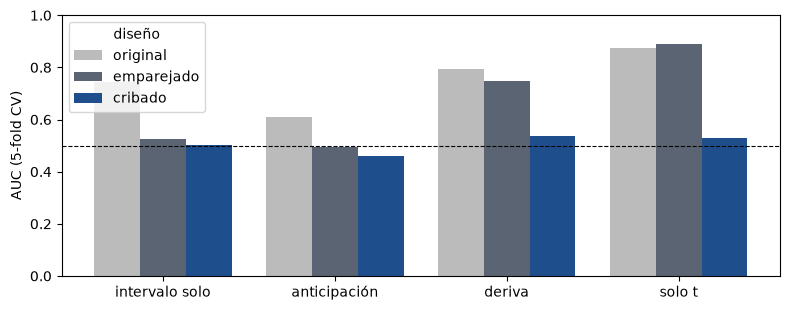

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.2))
senales = ["intervalo solo", "anticipación", "deriva", "solo t"]
x = np.arange(len(senales)); w = 0.8 / len(tabla_disenos)
colores = {"original": "#BBBBBB", "emparejado": "#5B6472", "cribado": "#1F4E8C"}
for k, (nombre, fila) in enumerate(tabla_disenos.iterrows()):
    ax.bar(x + (k - (len(tabla_disenos) - 1) / 2) * w, [fila[s] for s in senales], w,
           color=colores[nombre], label=nombre)
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(senales); ax.set_ylim(0, 1); ax.set_ylabel("AUC (5-fold CV)")
ax.legend(title="diseño"); plt.tight_layout(); plt.show()


**Lectura**:

1. **Intervalo**: en el diseño original, el tiempo entre exploraciones
   separa las clases sin mirar ninguna imagen. El emparejamiento por
   intervalo lo lleva al azar.
2. **Época**: en el original, el año de t-1 difiere entre grupos; la
   "anticipación" aparente venía de cambios de equipo y procesado entre
   años. Emparejando por fecha desaparece.
3. **Tipo de exploración**: en el diseño emparejado, la t de los casos casi
   nunca es un cribado (era la exploración diagnóstica, con vistas de
   compresión focal o magnificación). La deriva medía en parte "vista
   ampliada frente a vista normal". La prueba más clara es la columna
   "solo t": en el diseño emparejado la exploración t sola da ≈0.89, y en la
   cohorte de cribado, con t siempre cribado de campo completo, ≈0.53. El
   descriptor global reconocía el tipo de vista, no el cáncer.

Además, BI-RADS 4/5 no es cáncer (la mayoría de esas biopsias son
benignas): la cohorte de cribado define los casos por anatomía patológica.

Lección para cualquier estudio longitudinal de mamografía: antes de creer
una señal, comprobar "intervalo solo", el año de adquisición y el tipo de
exploración, y exigir un control positivo.

## Conclusiones y siguientes pasos

Resultados de referencia (`results/embed_longitudinal_cribado.txt` y
`results/embed_lesion_site_cribado*.txt`):

- **Mamografía entera**: el descriptor global no ve la lesión (control
  positivo ≈ 0.53), así que su nulo de anticipación no es informativo.
- **En el sitio de la lesión**: la topología detecta el cáncer en t
  (≈ 0.67–0.69, significativo). Un cribado antes, en el mismo sitio, el
  análisis 1:1 con 82 pares no ve nada (≈ 0.50), pero con más datos
  (todas las vistas, 3 controles) aparece un **efecto modesto y
  consistente** (≈ 0.57): local, no explicado por edad, densidad ni BI-RADS
  B, y replicado con controles nuevos emparejados por edad (secciones
  6b–6c). Es un candidato a precursor, pendiente de validación externa.
- El resultado metodológico, los **tres confusores**, es independiente de
  ese nulo y es probablemente la aportación más útil.

Siguientes pasos:
- Validación externa del efecto de las secciones 6b–6c en CSAW-CC, con el
  análisis fijado de antemano: ventana de 512 px en el sitio de la lesión,
  3 controles emparejados por intervalo, fecha, vista y edad, y regresión
  logística condicional ajustada por densidad y BI-RADS B.
